# 02 · Análisis Exploratorio Orientado a Modelado (EDA)
## Módulo 3 — Feature Engineering & Modelado Supervisado

---

### 🔒 Regla Fundamental: EDA Exclusivo sobre TRAIN (*Train-Only EDA*)
En el desarrollo de modelos de Machine Learning, evaluar o tomar decisiones analíticas observando el conjunto de prueba (*Test*) constituye **Data Leakage a través del analista**. 

Cualquier decisión tomada en esta etapa (identificación de categorías raras, cálculo de proporciones de nulos o umbrales de imputación) se calculará **únicamente sobre `train_ecommerce.csv`**. El conjunto de prueba permanecerá completamente aislado para evaluar el rendimiento real en producción.

**Objetivos de este cuaderno:**
1. **Univariado:** Analizar cardinalidad, varianza y presencia de micro-categorías en $X_{train}$.
2. **Bivariado:** Evaluar el poder de asociación de cada variable frente al Target (`Cluster`) mediante pruebas estadísticas.
3. **Diagnóstico de Nulos:** Confirmar patrones de nulos informativos (*MNAR*).
4. **Entregable:** Generar el reporte estructurado de decisiones que consumirán los módulos de Limpieza e Ingeniería de Variables.

In [1]:
# ==============================================================================
# PARTE 1: CARGA DE TRAIN Y CONFIGURACIÓN INICIAL
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual para pandas y gráficos
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
sns.set_theme(style="whitegrid")

# 1. Cargar únicamente el conjunto de entrenamiento
ruta_train = 'data_processed/train_ecommerce.csv'  # O tu ruta absoluta si aplica
train_df = pd.read_csv(ruta_train)

print(f"📦 Conjunto de Entrenamiento cargado: {train_df.shape[0]} filas × {train_df.shape[1]} columnas.")

# Separamos el Target (Cluster) de las variables explicativas (X)
target_col = 'Cluster'
X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]

print(f"🎯 Distribución del Target en Train (Clúster):")
display(y_train.value_counts(normalize=True).round(4) * 100)

📦 Conjunto de Entrenamiento cargado: 8086 filas × 62 columnas.
🎯 Distribución del Target en Train (Clúster):


Cluster
1   55.630
0   44.370
Name: proportion, dtype: float64

## 2. Análisis Univariado (Forma, Cardinalidad y Categorías Raras)

Antes de medir el poder predictivo, debemos auditar la salud individual de cada variable explicativa en el conjunto de entrenamiento:
* **Cardinalidad:** Número de valores únicos por variable.
* **Prevalencia de Cero Varianza:** Detectar variables dominadas por una sola categoría (>95%).
* **Categorías Raras (< 1%):** Identificar categorías diminutas que generan dispersión o ruido en los algoritmos de árbol o regresión.

In [8]:
# ==============================================================================
# PARTE 2: RESUMEN ANALÍTICO UNIVARIADO
# ==============================================================================

def reporte_univariado_categorico(df, umbral_rara=0.01, umbral_dominante=0.95):
    resumen = []
    total_filas = len(df)
    
    for col in df.columns:
        vc = df[col].value_counts(dropna=False, normalize=True)
        num_unicos = df[col].nunique(dropna=False)
        nulos_cant = df[col].isnull().sum()
        pct_nulos = (nulos_cant / total_filas) * 100
        
        # Moda y su frecuencia
        top_cat = vc.index[0] if len(vc) > 0 else np.nan
        pct_top = vc.iloc[0] * 100 if len(vc) > 0 else 0
        
        # Conteo de categorías raras (< 1%)
        cats_raras = (vc[vc < umbral_rara].count())
        
        # Alerta de dominancia
        alerta_dominante = "⚠️ Dominante (>95%)" if (pct_top >= umbral_dominante * 100) else "OK"
        
        resumen.append({
            'Variable': col,
            'Valores Únicos': num_unicos,
            '% Nulos': round(pct_nulos, 2),
            'Categoría Moda': top_cat,
            '% Frec. Moda': round(pct_top, 2),
            'Cant. Cats Raras (<1%)': cats_raras,
            'Estado Varianza': alerta_dominante
        })
        
    return pd.DataFrame(resumen)

reporte_uni = reporte_univariado_categorico(X_train)

print("📊 RESUMEN UNIVARIADO DE VARIABLES EN TRAIN:")
display(reporte_uni.sort_values(by='% Nulos', ascending=False).head(20))

📊 RESUMEN UNIVARIADO DE VARIABLES EN TRAIN:


,Variable,Valores Únicos,% Nulos,Categoría Moda,% Frec. Moda,Cant. Cats Raras (<1%),Estado Varianza
0,actual_time,22,0.000,Other,28.420,0,OK
1,age,8,0.000,25 - 34 años,27.170,0,OK
2,community_building,4,0.000,More,45.570,0,OK
3,community_membership_family,2,0.000,No,72.580,0,OK
4,community_membership_hobbies,2,0.000,No,54.870,0,OK
5,community_membership_none,2,0.000,No,75.860,0,OK
6,community_membership_other,2,0.000,No,81.030,0,OK
7,community_membership_political,2,0.000,No,90.550,0,OK
8,community_membership_professional,2,0.000,No,69.010,0,OK
9,community_membership_religious,2,0.000,No,93.020,0,OK


### 2.1 Visualización de Distribuciones Categóricas Clave (Univariado y Bivariado)

Para complementar la tabla analítica y entender el comportamiento del conjunto de entrenamiento (`Train`), seleccionamos un grupo de variables estratégicas de negocio. Evaluaremos:
1. **Frecuencia Relativa (%) Univariada:** La proporción de cada categoría en la muestra.
2. **Relación Bivariada con el Target (`Cluster`):** Cómo se distribuye la masa de cada categoría entre el **Clúster 1 (Motor Comercial)** y el **Clúster 0 (Consumidor Cauto)**.

C:\Users\Matiu\AppData\Local\Temp\ipykernel_4424\2388750803.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Matiu\AppData\Local\Temp\ipykernel_4424\2388750803.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Matiu\AppData\Local\Temp\ipykernel_4424\2388750803.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Matiu\AppData\Local\Temp\ipykernel_4424\2388750803.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` 

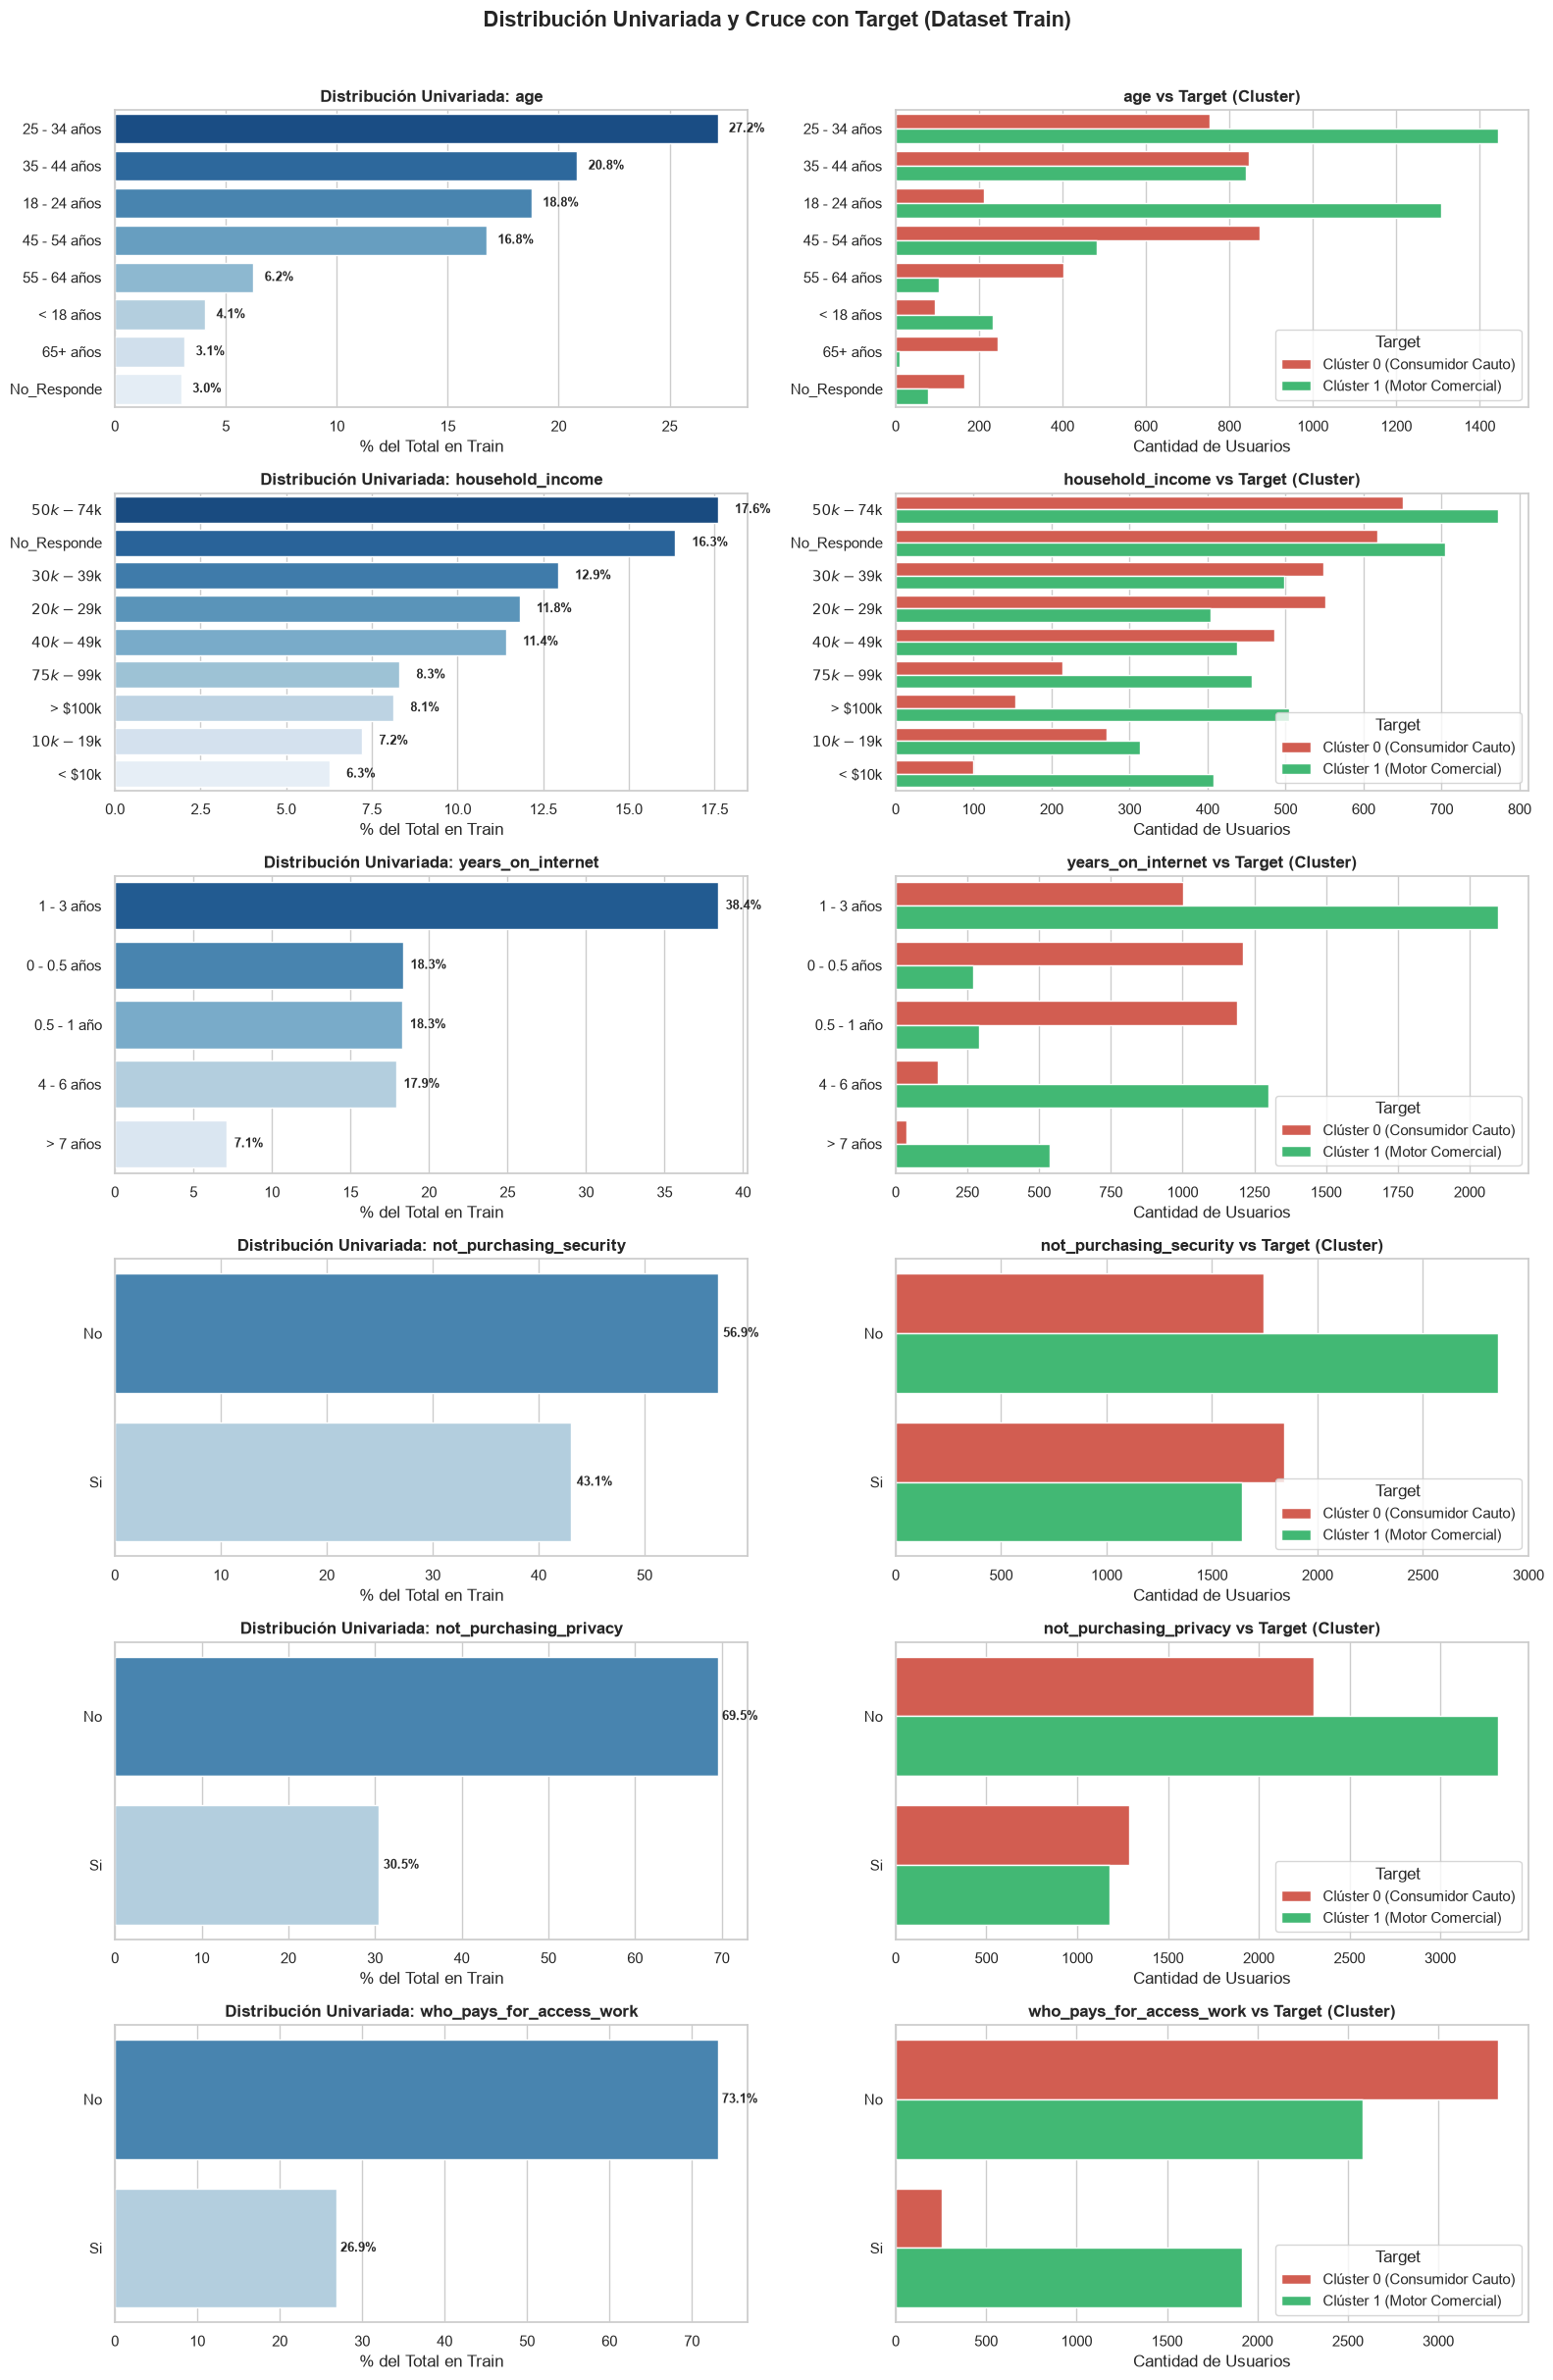

In [9]:
# ==============================================================================
# VISUALIZACIÓN DE VARIABLES CATEGÓRICAS CLAVE (UNIVARIADO Y BIVARIADO CON TARGET)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Lista de variables estratégicas para visualización
vars_visuales = [
    'age', 
    'household_income', 
    'years_on_internet', 
    'not_purchasing_security', 
    'not_purchasing_privacy',
    'who_pays_for_access_work'
]

# Unimos X_train e y_train temporalmente solo para graficar
df_train_plot = X_train.copy()
df_train_plot['Target_Cluster'] = y_train.map({
    1: 'Clúster 1 (Motor Comercial)', 
    0: 'Clúster 0 (Consumidor Cauto)'
})

# Configuración de la figura: 2 columnas por cada variable (Univariado vs Bivariado)
fig, axes = plt.subplots(nrows=len(vars_visuales), ncols=2, figsize=(16, 4 * len(vars_visuales)))
fig.suptitle('Distribución Univariada y Cruce con Target (Dataset Train)', fontsize=16, fontweight='bold', y=1.01)

paleta_target = {'Clúster 1 (Motor Comercial)': '#2ecc71', 'Clúster 0 (Consumidor Cauto)': '#e74c3c'}

for i, col in enumerate(vars_visuales):
    # --- 1. Gráfico Univariado (% del total) ---
    order_cat = df_train_plot[col].value_counts().index
    
    # Calculamos porcentajes univariados
    df_perc = df_train_plot[col].value_counts(normalize=True).reset_index()
    df_perc.columns = [col, 'Porcentaje']
    df_perc['Porcentaje'] = df_perc['Porcentaje'] * 100
    
    sns.barplot(
        data=df_perc, 
        y=col, 
        x='Porcentaje', 
        ax=axes[i, 0], 
        palette='Blues_r', 
        order=order_cat
    )
    axes[i, 0].set_title(f'Distribución Univariada: {col}', fontsize=12, fontweight='bold')
    axes[i, 0].set_xlabel('% del Total en Train')
    axes[i, 0].set_ylabel('')
    
    # Anotaciones numéricas en barras
    for p in axes[i, 0].patches:
        width = p.get_width()
        if width > 0:
            axes[i, 0].annotate(f'{width:.1f}%', (width + 0.5, p.get_y() + p.get_height()/2.),
                                ha='left', va='center', fontsize=9, fontweight='bold')

    # --- 2. Gráfico Bivariado con Target (% dentro de la categoría) ---
    sns.countplot(
        data=df_train_plot, 
        y=col, 
        hue='Target_Cluster', 
        ax=axes[i, 1], 
        palette=paleta_target, 
        order=order_cat
    )
    axes[i, 1].set_title(f'{col} vs Target (Cluster)', fontsize=12, fontweight='bold')
    axes[i, 1].set_xlabel('Cantidad de Usuarios')
    axes[i, 1].set_ylabel('')
    axes[i, 1].legend(title='Target', loc='lower right')

plt.tight_layout()
plt.show()

## 3. Análisis Bivariado Cuantitativo ($\chi^2$ y V de Cramér)

Para seleccionar las variables con mayor poder predictivo antes de la etapa de ingeniería de características, evaluamos cuantitativamente la relación entre cada variable categórica explicativa ($X_{train}$) y el Target (`Cluster`):

1. **Prueba Chi-Cuadrado ($\chi^2$):** Evalúa la hipótesis nula ($H_0$) de independencia estadística. Un $p\text{-value} < 0.05$ confirma la existencia de una relación significativa.
2. **V de Cramér ($V$):** Mide la **fuerza de la asociación** entre $0$ (independencia total) y $1$ (asociación perfecta), ajustando por el número de categorías.

$$V = \sqrt{\frac{\chi^2}{N \cdot \min(k-1, r-1)}}$$

In [10]:
# ==============================================================================
# PARTE 3: PRUEBAS ESTADÍSTICAS BIVARIADAS (CHI-CUADRADO Y V DE CRAMÉR)
# ==============================================================================
from scipy.stats import chi2_contingency

def evaluar_asociacion_categorica(X, y):
    resultados = []
    n = len(y)
    
    for col in X.columns:
        # Tabla de contingencia
        tabla_contingencia = pd.crosstab(X[col].fillna('FALTANTE_NA'), y)
        
        # Test Chi-Cuadrado
        chi2, p_val, dof, _ = chi2_contingency(tabla_contingencia)
        
        # V de Cramér
        k = tabla_contingencia.shape[0] # categorías de X
        r = tabla_contingencia.shape[1] # clases de Target (2)
        min_dim = min(k - 1, r - 1)
        
        cramer_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0.0
        
        # Clasificación del efecto
        if cramer_v >= 0.30:
            fuerza = '🔥 Fuerte'
        elif cramer_v >= 0.15:
            fuerza = '⚡ Moderada'
        elif cramer_v >= 0.05:
            fuerza = '🔹 Débil'
        else:
            fuerza = '⚪ Despreciable'
            
        resultados.append({
            'Variable': col,
            'Chi2': round(chi2, 2),
            'p-value': round(p_val, 5),
            'Significativo (p<0.05)': 'Sí' if p_val < 0.05 else 'No',
            'V_Cramer': round(cramer_v, 4),
            'Fuerza Asociación': fuerza
        })
        
    df_res = pd.DataFrame(resultados).sort_values(by='V_Cramer', ascending=False)
    return df_res

# Evaluamos sobre el conjunto de entrenamiento
ranking_bivariado = evaluar_asociacion_categorica(X_train, y_train)

print("🏆 TOP 20 VARIABLES CON MAYOR PODER PREDICTIVO EN TRAIN:")
display(ranking_bivariado.head(20))

🏆 TOP 20 VARIABLES CON MAYOR PODER PREDICTIVO EN TRAIN:


,Variable,Chi2,p-value,Significativo (p<0.05),V_Cramer,Fuerza Asociación
30,primary_place_of_www_access,3546.360,0.000,Sí,0.662,🔥 Fuerte
24,major_occupation,3216.510,0.000,Sí,0.631,🔥 Fuerte
28,primary_computing_platform,3097.390,0.000,Sí,0.619,🔥 Fuerte
0,actual_time,2876.020,0.000,Sí,0.596,🔥 Fuerte
57,years_on_internet,2821.100,0.000,Sí,0.591,🔥 Fuerte
52,web_page_creation,1687.700,0.000,Sí,0.457,🔥 Fuerte
1,age,1520.890,0.000,Sí,0.434,🔥 Fuerte
55,who_pays_for_access_self,1386.280,0.000,Sí,0.414,🔥 Fuerte
60,who_pays_for_access_work,1279.380,0.000,Sí,0.398,🔥 Fuerte
56,willingness_to_pay_fees,1143.710,0.000,Sí,0.376,🔥 Fuerte


## 4. Diagnóstico de Nulos Informativos (MNAR)

En encuestas sobre conducta y privacidad, los valores ausentes o la respuesta explícita `No_Responde` **no ocurren al azar (MNAR - Missing Not At Random)**. 

Calculamos la tasa del Target (`Clúster 1 - Motor Comercial`) cuando el dato está **Presente vs. Ausente/No Responde**. Si la diferencia en la tasa de respuesta es superior a **5 puntos porcentuales (pp)**, el nulo contiene una señal de negocio activa y **no debe imputarse a la ciega**, sino conservarse mediante banderas indicadoras (`_missing`).

In [12]:
# ==============================================================================
# PARTE 4: EVALUACIÓN DE NULOS INFORMATIVOS Y REPORTE ESTRUCTURADO
# ==============================================================================

def detectar_nulos_informativos(X, y, umbral_pp=5.0):
    nulos_inf = []
    
    for col in X.columns:
        # Evaluamos nulos explícitos (NaN) o categorías implícitas ('No_Responde')
        es_ausente = X[col].isnull() | (X[col].astype(str).str.lower().str.contains('no_responde|not_informed|uninformed'))
        
        if es_ausente.sum() > 0:
            tasa_ausente = y[es_ausente].mean() * 100
            tasa_presente = y[~es_ausente].mean() * 100
            diferencia_pp = abs(tasa_ausente - tasa_presente)
            
            if diferencia_pp >= umbral_pp:
                nulos_inf.append({
                    'Variable': col,
                    'Tasa_Ausente_%': round(tasa_ausente, 2),
                    'Tasa_Presente_%': round(tasa_presente, 2),
                    'Diferencia_pp': round(diferencia_pp, 2)
                })
                
    return pd.DataFrame(nulos_inf).sort_values(by='Diferencia_pp', ascending=False)

df_nulos_inf = detectar_nulos_informativos(X_train, y_train)

print("🚨 VARIABLES CON NULOS O RESPUESTAS DE EVASIÓN ALTAMENTE INFORMATIVAS (Diferencia > 5pp):")
display(df_nulos_inf.head(10))

# ------------------------------------------------------------------------------
# CONSOLIDACIÓN DEL REPORTE ESTRUCTURADO DE DECISIONES (PARA SIGUIENTES NOTEBOOKS)
# ------------------------------------------------------------------------------
reporte_decisiones_eda = {
    'candidatas_descarte_baja_varianza': reporte_uni[reporte_uni['Estado Varianza'] != 'OK']['Variable'].tolist(),
    'top_variables_predictivas_cramer': ranking_bivariado[ranking_bivariado['V_Cramer'] >= 0.10]['Variable'].tolist(),
    'nulos_informativos_mnar': df_nulos_inf['Variable'].tolist() if not df_nulos_inf.empty else []
}

print("\n" + "="*75)
print("📌 REPORTE ESTRUCTURADO DE DECISIONES DE EDA (TRAIN ONLY) CONSOLIDADO:")
print(f"· Variables con baja varianza a eliminar (>95% dominante): {len(reporte_decisiones_eda['candidatas_descarte_baja_varianza'])}")
print(f"· Top variables predictivas (V de Cramér >= 0.10): {len(reporte_decisiones_eda['top_variables_predictivas_cramer'])}")
print(f"· Variables con nulos/evasión informativos (MNAR): {len(reporte_decisiones_eda['nulos_informativos_mnar'])}")
print("="*75)

🚨 VARIABLES CON NULOS O RESPUESTAS DE EVASIÓN ALTAMENTE INFORMATIVAS (Diferencia > 5pp):


,Variable,Tasa_Ausente_%,Tasa_Presente_%,Diferencia_pp
0,age,32.230,56.350,24.120
1,falsification_of_information,37.260,58.250,20.980



📌 REPORTE ESTRUCTURADO DE DECISIONES DE EDA (TRAIN ONLY) CONSOLIDADO:
· Variables con baja varianza a eliminar (>95% dominante): 0
· Top variables predictivas (V de Cramér >= 0.10): 37
· Variables con nulos/evasión informativos (MNAR): 2


## 5. Conclusiones y Diagnóstico para el Modelado (Train-Only EDA)

El Análisis Exploratorio orientado al modelado supervisado sobre el conjunto de entrenamiento ($N_{train}$) concluye con la generación del **Reporte Estructurado de Decisiones**, alineado con los requerimientos de la arquitectura del pipeline:

---

### A. Jerarquía de Poder Predictivo (Análisis de V de Cramér)
La evaluación de fuerza de asociación bivariada contra el Target (`Cluster`) confirmó la presencia de $37$ variables con capacidad predictiva estadísticamente relevante ($V \ge 0.10, p < 0.001$):

1. **Variables de Altísima Fuerza Predictiva ($V > 0.50$):**
   * `primary_place_of_www_access` ($V = 0.662$): El lugar principal de acceso a la web es el discriminador número 1 del mercado.
   * `major_occupation` ($V = 0.631$) y `primary_computing_platform` ($V = 0.619$): La profesión y el sistema operativo utilizado marcan brechas tecnológicas insalvables entre ambos segmentos.
   * `actual_time` ($V = 0.596$) y `years_on_internet` ($V = 0.591$): La dedicación y la antigüedad del usuario en la red completan el Top 5 de variables con mayor peso explicativo.
2. **Variables Demográficas y Económicas Clave ($0.20 \le V < 0.45$):**
   * La edad (`age`, $V = 0.434$), el financiamiento laboral (`who_pays_for_access_work`, $V = 0.398$) y los ingresos (`household_income`, $V = 0.226$) respaldan la caracterización socioeconómica descubierta en la etapa multivariante.

---

### B. Validación Empírica de Nulos e Indicadores de Evasión (MNAR)
El diagnóstico de patrones ausentes demostró con evidencia matemática que los nulos **no son aleatorios (Missing Not At Random)**:

| Variable Analizada | Tasa Target en Datos Presentes (%) | Tasa Target en Datos Ausentes / Evasión (%) | Brecha de Impacto (pp) | Diagnóstico |
| :--- | :---: | :---: | :---: | :--- |
| **`age`** | **$56.35\%$** | **$32.23\%$** | **$24.12 \text{ pp}$** 🚨 | **MNAR Severo** |
| **`falsification_of_information`** | **$58.25\%$** | **$37.26\%$** | **$20.98 \text{ pp}$** 🚨 | **MNAR Severo** |

**💡 Insight Técnico para el Pipeline:**
Cuando un usuario decide no revelar su edad o evade responder sobre falsificación de información, la probabilidad de pertenecer al **Clúster 1 (Motor Comercial)** cae en más de $20$ puntos porcentuales, desplazándose masivamente hacia el **Clúster 0 (Consumidor Cauto)**. Imputar estos valores por la moda destruirá la señal predictiva. Se dictamina conservar los indicadores explícitos de omisión (`_missing` / `No_Responde`).

---

### C. Consolidación del Reporte Estructurado de Decisiones

| Criterio de Selección / Limpieza | Resultado Cuantitativo | Acción para Notebooks 03 a 06 |
| :--- | :---: | :--- |
| **Variables con Varianza Cero (>95% dominancia)** | $0$ variables | Se conserva el $100\%$ de la base de características inicial. |
| **Filtro de Relevancia ($V \ge 0.10$)** | **$37$ variables** | Constituyen la base oficial de predictores para la ingeniería de variables. |
| **Variables MNAR Informativas (Diferencia > 5pp)** | **$2$ variables (`age`, `falsification`)** | Se prohíbe la imputación simple; se generan indicadores de evasión. |

**🏁 Transición al Siguiente Módulo:**
Con el reporte analítico consolidado, se procede al cuaderno **`03_limpieza_y_outliers.ipynb`**, donde se ejecutará la depuración de datos categóricos y la detección multivariada de anomalías espaciales sobre el conjunto $X_{train}$.